In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np

In [2]:
with open('resources/soil_parameters.json', 'r') as f:
    param_list = json.load(f)
    
# Convert list of dicts into a dict keyed by 'soil_type'
soil_params = {
    p["soil_type"]: {k: v for k, v in p.items() if k != "soil_type"} for p in param_list
}

for soil_type, params in soil_params.items():
    params['psi_sat'] = params['psi_sat'] * 98.0665  # Convert from cm H2O to Pa

# For each soil type create a results dict with an empty array for 11 soil potentials
soil_results = {
    soil_type: np.zeros(100) for soil_type in soil_params.keys()
}

for i, wetness in enumerate(np.linspace(0.1, 1, 100)):
    for soil_type, params in soil_params.items():
        soil_potential = (params['psi_sat']) * (wetness ** (-params['b']))
        
        soil_results[soil_type][i] = soil_potential

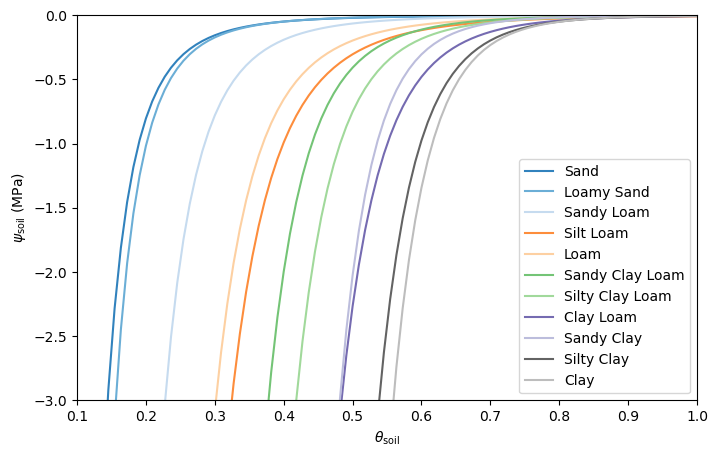

In [ ]:
cmap = plt.get_cmap('tab20c')

label = ['Sand', 'Loamy Sand', 'Sandy Loam', 'Silt Loam', 'Loam', 'Sandy Clay Loam', 
         'Silty Clay Loam', 'Clay Loam', 'Sandy Clay', 'Silty Clay', 'Clay']

fig, ax = plt.subplots(figsize=(8, 5))
for i, (soil_type, potentials) in enumerate(soil_results.items()):
    ax.plot(np.linspace(0.1, 1, 100), (potentials / 1e6), label=label[i], 
            color=cmap(i / len(soil_results)))
ax.set_xlabel('$\\theta_{\\rm soil}$')
ax.set_ylabel('$\\psi_{\\rm soil}$ (MPa)')
ax.set_xlim(0.1, 1)
ax.set_ylim(-3, 0)
ax.legend()
plt.show()